# Pet segmentation with a new backbone and decoder (MobileOne + LR-ASPP)

This notebook re-does the existing `segmentation_deeplab-v3-plus_oxford-iiit.ipynb`
use case — 3-class Oxford-IIIT Pets segmentation (pet / border / background)
via `SegmentationAlbumentationsDataLoader` + `TrainingDriver` — with two of
the new components added to this plan: the **MobileOne-S1** backbone (§2.1,
in place of the original's `EfficientNetLiteB0`) and the **LR-ASPP** decoder
(§4.1, in place of the original's `deeplab_v3_plus`). Same dataset (the
[Oxford-IIIT Pets dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/),
Parkhi et al. 2012, already downloaded and extracted into `oxford_iiit/`),
same augmentation recipe, same `label_shift=1` trimap remap.

**Real training, real data** — not a synthetic demo. Trained at 256x256
(matching the original's resolution) on GPU (an NVIDIA RTX PRO 1000, once
`tensorflow[and-cuda]`'s pip-distributed CUDA/cuDNN libraries were installed
and `LD_LIBRARY_PATH` pointed at them — see the next cell).

The backbone loads real ImageNet-pretrained weights (`plan.md` §12.4) and
stays **frozen for the entire run** (`unfreezed_epochs=0`) — this is
transfer learning onto a small dataset, not training a randomly-initialized
backbone from scratch, and deliberately not the original recipe's
unfrozen fine-tuning phase either. A first pass at 192x192/20 epochs with
the original recipe's `1e-4` LR and `0.1` label smoothing produced visibly
worse boundary predictions than the fine-tuned DeepLabv3+ baseline
(compare `show_results` in both notebooks) — expected, since a frozen,
generic-ImageNet backbone's features were never adapted to this task's
precise trimap boundaries. This version keeps the backbone frozen (by
choice) but re-tunes everything *else* around that constraint: input
resolution back to 256x256, a much higher decoder learning rate (`1e-3`,
not sized to protect pretrained features that aren't training anyway), 80
epochs with `ReduceLROnPlateau` (cheap, since a frozen backbone skips the
backbone's backward pass), no label smoothing, and a Tversky `delta=0.7`
biased further toward recall - the border class was under-predicted
(missed pixels), not over-predicted. See the inline comments on the loss/
optimizer/`TrainingDriver` cell below for the full reasoning on each change.


## Bugs found and fixed while building the classification notebook, also relevant here

The companion `classification_repvit_flowers.ipynb` notebook found and fixed
five real, pre-existing bugs in this library while getting real training
working for the first time (`plan.md` §10/§13 Phase 8). Three of them are in
`dataset_utils.py`'s shared data-loading machinery
(`WorkerProcess`/`BrokerProcess`/`aug_function_parallel`) and apply equally
to `SegmentationAlbumentationsDataLoader`, used here:

1. A worker-pool startup race (`_warm_up_workers` now probes the whole pool,
   not just one worker, before the loader is handed to a `tf.data` pipeline).
2. Replies from the worker pool were assumed to arrive in send order, which
   isn't guaranteed — `aug_function_parallel` now tags each request with its
   batch index and matches replies to slots by that index.
3. A shared ZMQ client socket across the train/val/test pipelines needed a
   lock around each batch round-trip.

The two other bugs (`training_utils.py`'s `Model` import, and a numpy
scalar-assignment issue specific to the classification label path) don't
apply to segmentation masks (`aug_msk` is a full 2-D reshape, not a scalar
assignment) or to this backbone (MobileOne has a full 5-tap feature pyramid,
so `deep_layer`'s default stride assumption holds - unlike RepViT/FastViT's
patchify stems). See that notebook for the full detail on all five.


## Imports

`swiss_army_keras` must be imported *before* `tensorflow` - see
`repvit_pp-liteseg_water-segmentation.ipynb` for why (`TF_USE_LEGACY_KERAS`
QAT caveat).


In [1]:
import swiss_army_keras  # noqa: F401 - import before tensorflow
import pathlib
import tensorflow as tf

tf.random.set_seed(0)

from swiss_army_keras.dataset_utils import SegmentationAlbumentationsDataLoader
from swiss_army_keras.models import lr_aspp
from swiss_army_keras.optimizers import AdaBeliefOptimizer
from swiss_army_keras.training_utils import TrainingDriver
from swiss_army_keras import losses, metrics
import albumentations as albu

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)


I0000 00:00:1790064836.159225 3605561 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790064836.194325 3605561 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790064836.883957 3605561 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/matteo/Documents/work/SAK/swiss-army-keras/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: Tqdm

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


/home/matteo/Documents/work/SAK/swiss-army-keras/.venv/lib/python3.12/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version
/home/matteo/Documents/work/SAK/swiss-army-keras/swiss_army_keras/_backbone_zoo.py:70: UserWarning: 
----------------------------------------
Could not import `efficientnet_lite` (from the `efficientnet-lite-keras` package) - EfficientNetLiteB0-B4 backbones will not be available. Every other backbone is unaffected.
----------------------------------------
  warnings.warn(
W0000 00:00:1790064839.626631 3605561 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or 

## Dataset

The Oxford-IIIT Pets dataset (images + pixel-wise trimaps: 1=pet,
2=background, 3=border) has already been downloaded and extracted into
`oxford_iiit/images/` and `oxford_iiit/annotations/trimaps/` alongside this
notebook.


In [2]:
dataset_path = "/home/matteo/Documents/work/SAK/swiss-army-keras/docs/source/notebooks/oxford_iiit/"
assert (pathlib.Path(dataset_path) / "images").exists()
assert (pathlib.Path(dataset_path) / "annotations" / "trimaps").exists()

# The Pets images.tar.gz bundles a handful of stray .mat (MATLAB) annotation
# files alongside the .jpg images in images/ - the original notebook deletes
# these right after extraction (`rm *.mat`); do the same here, since the
# data loader lists every file in images_dir and tf.image.decode_jpeg fails
# on a non-image file with `Unknown image file format`.
mat_files = list((pathlib.Path(dataset_path) / "images").glob("*.mat"))
for f in mat_files:
    f.unlink()
if mat_files:
    print(f"removed {len(mat_files)} stray .mat file(s) from images/")

print(dataset_path)


/home/matteo/Documents/work/SAK/swiss-army-keras/docs/source/notebooks/oxford_iiit/


## Model: MobileOne-S1 backbone + LR-ASPP decoder

MobileOne (§2.1) has a genuine single-stride-2 stem (a full 5-tap feature
pyramid, stride 2/4/8/16/32), so `lr_aspp`'s defaults (`deep_layer=5`,
`shallow_layer=2`) apply directly - no override needed, unlike the
RepViT/FastViT case in the other new-backbone notebooks.

The backbone loads real ImageNet-pretrained weights (ported from `timm`,
`plan.md` §12.4 — pass the `.weights.h5` path produced by
`scripts/port_mobileone_weights.py` as `weights=`) and stays frozen
(`freeze_backbone=True`) for the whole training run below: only the
LR-ASPP decoder trains.

In [3]:
IMG_SIZE = 256
N_LABELS = 3  # pet / border / background

input_tensor = tf.keras.layers.Input((IMG_SIZE, IMG_SIZE, 3), batch_size=1)

X_decoder = lr_aspp(
    input_tensor,
    n_labels=N_LABELS,
    backbone="MobileOne-S1",
    num_filters=128,
    num_filters_shallow=48,
    activation="ReLU",
    batch_norm=True,
    weights="/home/matteo/Documents/work/SAK/swiss-army-keras/pretrained_weights/mobileone/MobileOne_S1.weights.h5",
    freeze_backbone=True,  # keep the pretrained backbone locked; only the decoder trains
    name="Pets",
)

OUT_stack = X_decoder(input_tensor)
model = tf.keras.models.Model([input_tensor], OUT_stack)
model.preprocessing = X_decoder.preprocessing
model.summary()


W0000 00:00:1790064860.045321 3605561 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1790064860.187702 3605561 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5699 MB memory:  -> device: 0, name: NVIDIA RTX PRO 1000 Blackwell Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(1, 256, 256, 3)]        0         
                                                                 
 model (Functional)          (1, 256, 256, 3)          3946840   
                                                                 
Total params: 3946840 (15.06 MB)
Trainable params: 333299 (1.27 MB)
Non-trainable params: 3613541 (13.78 MB)
_________________________________________________________________


## Augmentation pipeline (unchanged from the original notebook)


In [4]:
def get_training_augmentation(width=IMG_SIZE, height=IMG_SIZE):
    train_transform = [
        albu.HorizontalFlip(p=0.5),
        albu.VerticalFlip(p=0.10),
        albu.Compose([
            albu.OneOf([
                albu.ISONoise(p=1),
                albu.MultiplicativeNoise(p=1),
                albu.GaussNoise(p=1),
                albu.ImageCompression(p=1),
            ], p=1),
            albu.OneOf([
                albu.CLAHE(p=1),
                albu.RandomBrightnessContrast(p=1),
                albu.Sharpen(p=1),
                albu.Emboss(p=1),
                albu.RandomGamma(p=1),
            ], p=0.5),
            albu.OneOf([
                albu.Blur(blur_limit=5, p=1),
                albu.MedianBlur(blur_limit=5, p=1),
                albu.MotionBlur(blur_limit=5, p=1),
            ], p=0.25),
            albu.OneOf([
                albu.RandomBrightnessContrast(p=1),
                albu.HueSaturationValue(p=1),
                albu.RGBShift(p=1),
            ], p=0.25),
            albu.OneOf([
                albu.GridDistortion(p=0.5),
                albu.OpticalDistortion(distort_limit=0.3, shift_limit=0.05, p=1),
            ], p=0.25),
        ], p=0.5),
        albu.ToGray(p=0.2),
    ]
    return albu.Compose(train_transform)


## Data loader

Spins up `cpu_count() // 2` worker processes producing augmented
(image, mask) pairs over ZMQ. `label_shift=1` remaps the trimap's 1-indexed
classes ({1,2,3}) to 0-indexed ({0,1,2}) before one-hot encoding.
`normalization=model.preprocessing` ensures the exact normalization
MobileOne expects is applied consistently in both training and inference.


In [ ]:
loader = SegmentationAlbumentationsDataLoader(
    num_classes=N_LABELS,
    batch_size=16,
    width=IMG_SIZE,
    height=IMG_SIZE,
    dataset_path=dataset_path,
    masks_dir="annotations/trimaps",
    train_augmentations=get_training_augmentation(),
    label_shift=1,
    train_val_test_split=[0.8, 0.1, 0.1],
    normalization=model.preprocessing,
)
train_set, val_set, test_set = loader.build_datasets()


/tmp/ipykernel_3605561/253672635.py:31: UserWarning: Argument(s) 'shift_limit' are not valid for transform OpticalDistortion
  albu.OpticalDistortion(distort_limit=0.3, shift_limit=0.05, p=1),


Train Images are good to go


ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable


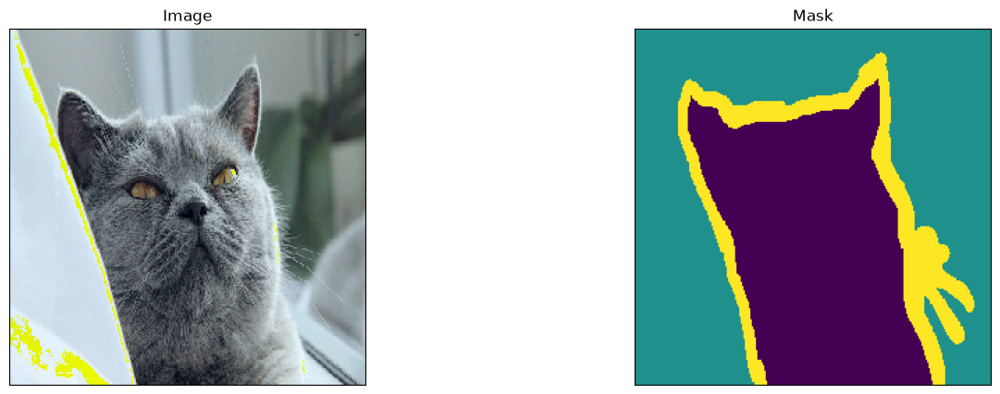

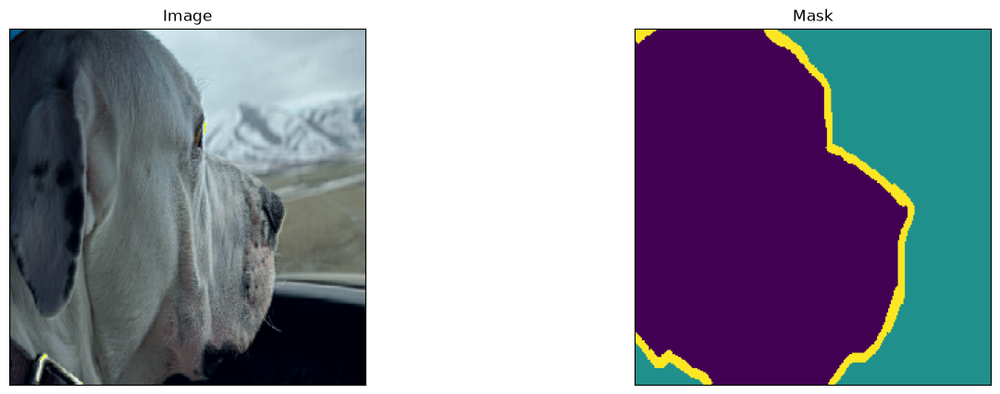

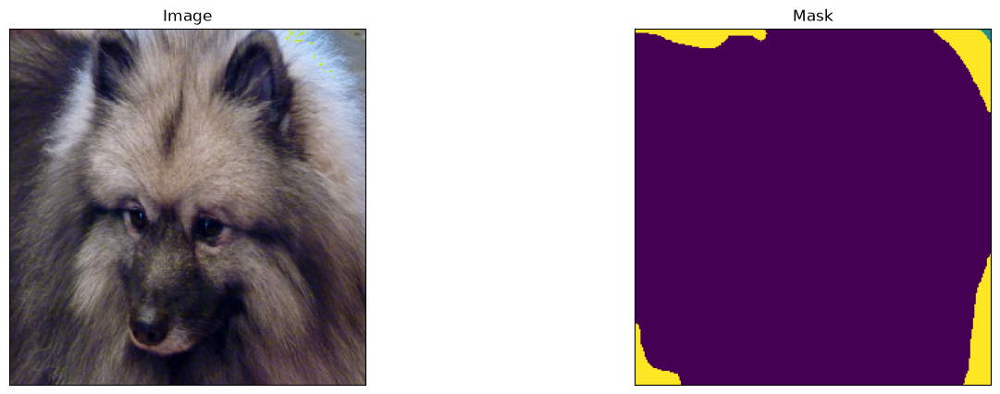

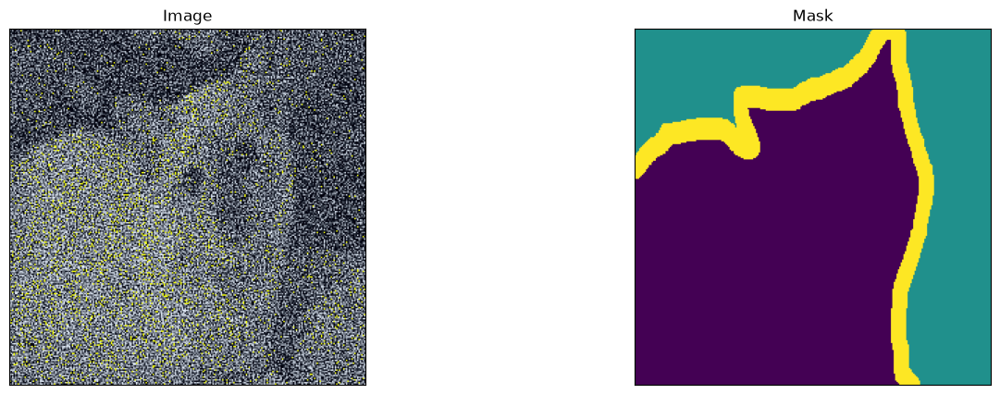

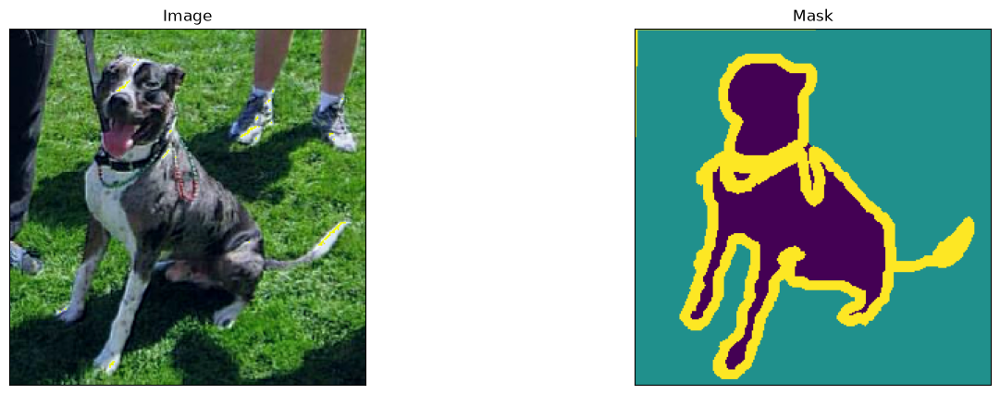

...

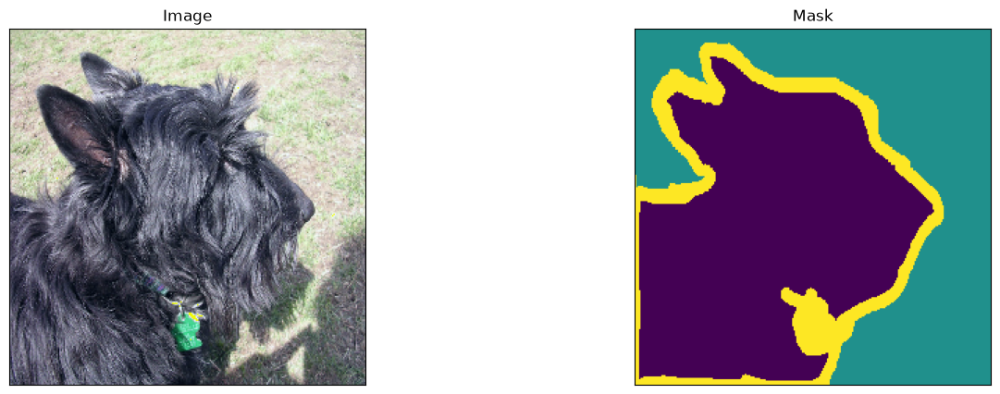

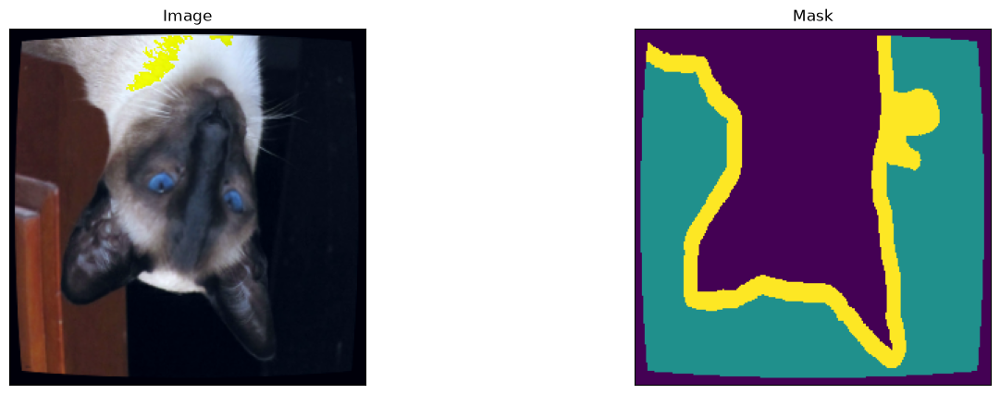

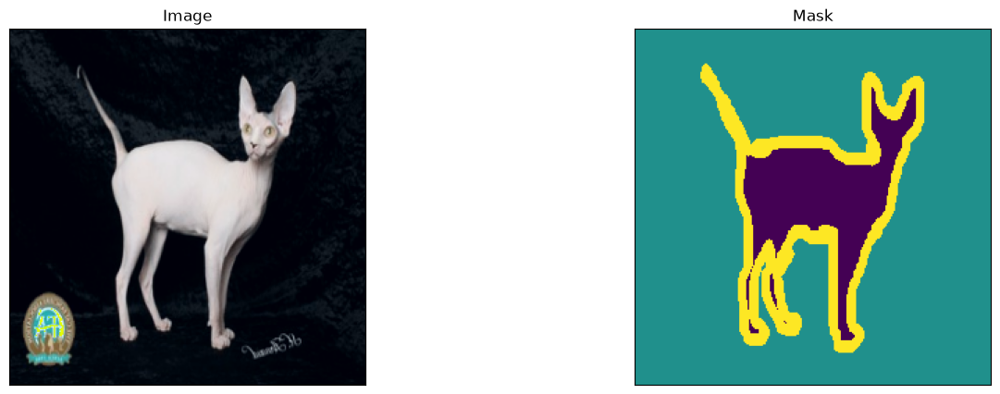

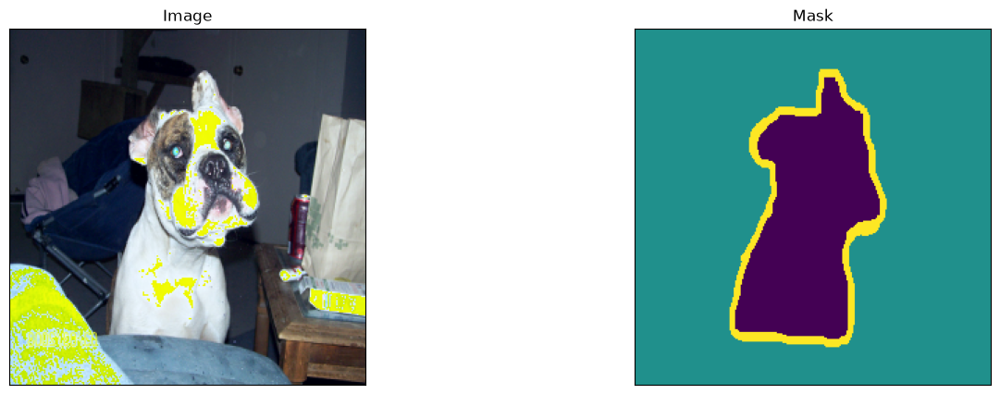

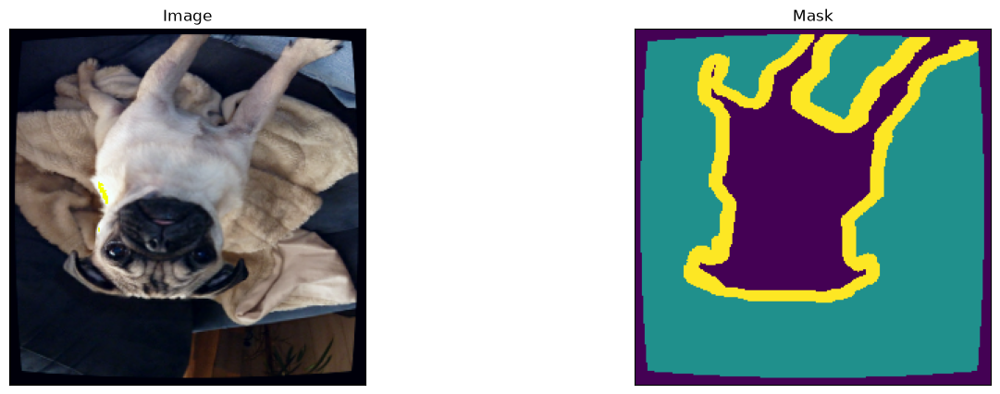

In [9]:
loader.show_images(dset="train", num_images=16)


## Train

The backbone loads real ImageNet-pretrained weights and stays frozen for
the full 80 epochs (`unfreezed_epochs=0`) — only the LR-ASPP decoder's own
weights are updated; the model-summary output above shows this directly
(non-trainable params dominate the total). Loss/optimizer/schedule are
tuned specifically for a frozen-backbone, from-scratch-decoder regime
(higher LR, more epochs, no label smoothing, recall-biased Tversky `delta`)
— see the inline comments in the cell below for the reasoning behind each.
Uses this library's `symmetrical_unified_focal_loss` wrapped in
`loss_adapter(..., from_logits=True)` — every decoder in this repo
(`lr_aspp` included) outputs raw logits, no final activation, so the loss
must apply softmax internally rather than assuming already-probability
inputs (the established convention in this repo — see the original
DeepLabv3+ notebook and `use_case_recipes.md`).

In [ ]:
loss = losses.loss_adapter(
    # delta=0.7 (up from the 0.6 default): tversky_coef's alpha weights
    # false negatives more heavily as it goes up (TP / (TP + alpha*FN +
    # (1-alpha)*FP)) - the border class was consistently under-predicted
    # (missed pixels, not over-predicted ones), so biasing further toward
    # recall should help it specifically.
    losses.symmetrical_unified_focal_loss(delta=0.7), from_logits=True,
    # label_smoothing=0.0 (down from 0.1): the border class is already a
    # thin minority of pixels - smoothing its already-sparse one-hot
    # target further shrinks an already weak gradient signal.
    label_smoothing=0.0,
)
accuracy = tf.keras.metrics.CategoricalAccuracy()
miou = metrics.MeanIOU(num_classes=N_LABELS)

td = TrainingDriver(
    model,
    "pets_mobileone_lraspp",
    # learning_rate=1e-3 (up from 1e-4, AdaBelief's own default): 1e-4 was
    # sized for fine-tuning a pretrained backbone without catastrophic
    # forgetting - irrelevant here, since only a small, randomly-
    # initialized decoder (see the trainable-param count in the
    # model-summary output above) is training. It can afford a much larger
    # step size.
    AdaBeliefOptimizer(learning_rate=1e-3, epsilon=1e-14),
    loss,
    [accuracy, miou],
    train_set,
    val_set,
    test_set,
    # epochs=80 (up from 20): a frozen backbone means no backbone backward
    # pass, so epochs are cheap here - a from-scratch decoder likely needs
    # more of them to converge than the original recipe's already-warm,
    # fine-tuned backbone did.
    epochs=80,
    unfreezed_epochs=0,  # keep the pretrained backbone locked for the whole run
    # Decay the LR once validation loss plateaus, rather than holding the
    # higher 1e-3 constant for all 80 epochs - complements the built-in
    # EarlyStopping(patience=20) already wired into TrainingDriver.
    callbacks=[
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=8, min_lr=1e-6
        ),
    ],
)
td.run()


Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(1, 256, 256, 3)]        0         
                                                                 
 model (Functional)          (1, 256, 256, 3)          3946840   
                                                                 
Total params: 3946840 (15.06 MB)
Trainable params: 333299 (1.27 MB)
Non-trainable params: 3613541 (13.78 MB)
_________________________________________________________________
Epoch 1/80


I0000 00:00:1790064986.038749 3610238 cuda_dnn.cc:461] Loaded cuDNN version 92600
W0000 00:00:1790064987.283380 3610234 bfc_allocator.cc:383] Garbage collection: deallocate free memory regions (i.e., allocations) so that we can re-allocate a larger region to avoid OOM due to memory fragmentation. If you see this message frequently, you are running near the threshold of the available device memory and re-allocation may incur great performance overhead. You may try smaller batch sizes to observe the performance impact. Set TF_ENABLE_GPU_GARBAGE_COLLECTION=false if you'd like to disable this feature.
W0000 00:00:1790064988.036886 3610234 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 736.00MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1790064988.036932 3610234 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying 

 57/369 [===>..........................] - ETA: 36s - loss: 0.4159 - categorical_accuracy: 0.7857 - mean_iou: 0.5129

Corrupt JPEG data: premature end of data segment


300/369 [=======================>......] - ETA: 8s - loss: 0.3687 - categorical_accuracy: 0.8218 - mean_iou: 0.5719

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9


... (38 outputs left out)

369/369 [==============================] - 67s 181ms/step - loss: 0.3185 - categorical_accuracy: 0.8554 - mean_iou: 0.6338 - val_loss: 0.2893 - val_categorical_accuracy: 0.8795 - val_mean_iou: 0.6738 - lr: 0.0010
Epoch 11/80
 59/369 [===>..........................] - ETA: 55s - loss: 0.3056 - categorical_accuracy: 0.8656 - mean_iou: 0.6505

Corrupt JPEG data: premature end of data segment


 99/369 [=======>......................] - ETA: 47s - loss: 0.3083 - categorical_accuracy: 0.8635 - mean_iou: 0.6487

KeyboardInterrupt: 

## Results


1/1 [==============================] - 2s 2s/step


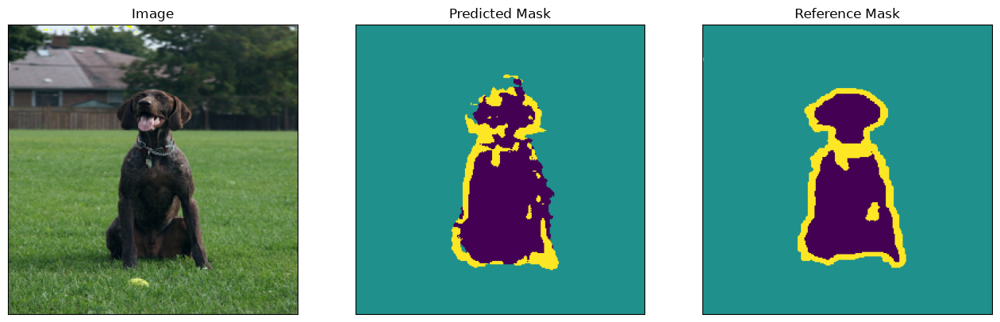

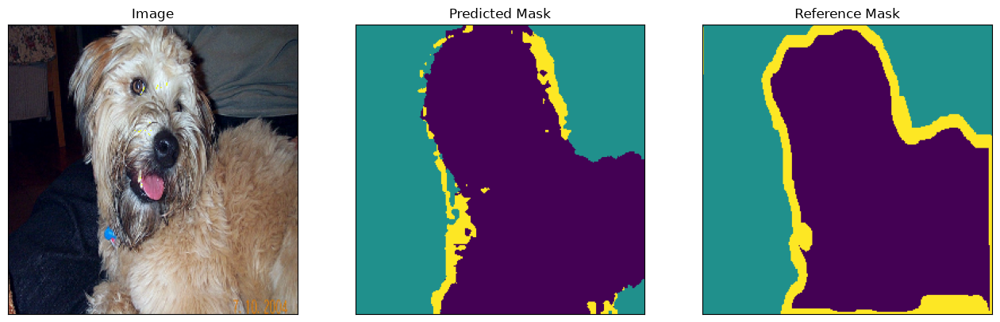

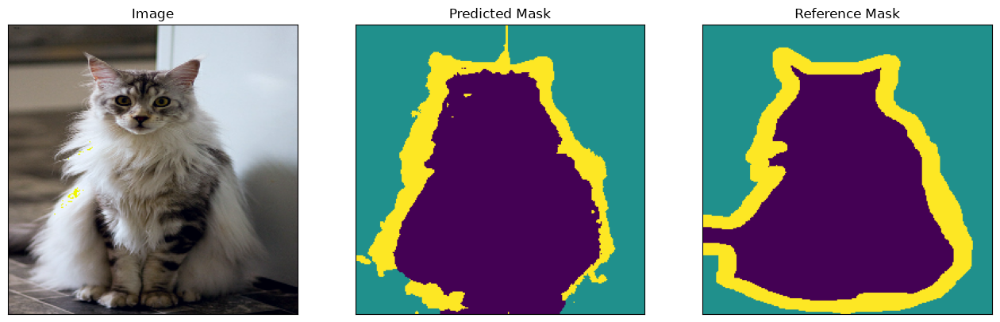

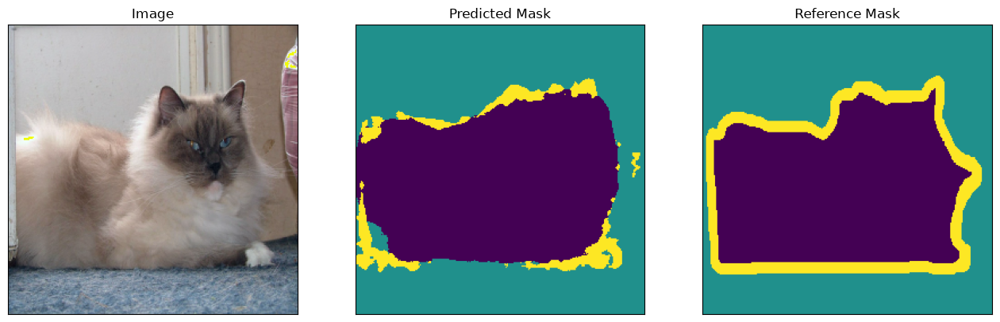

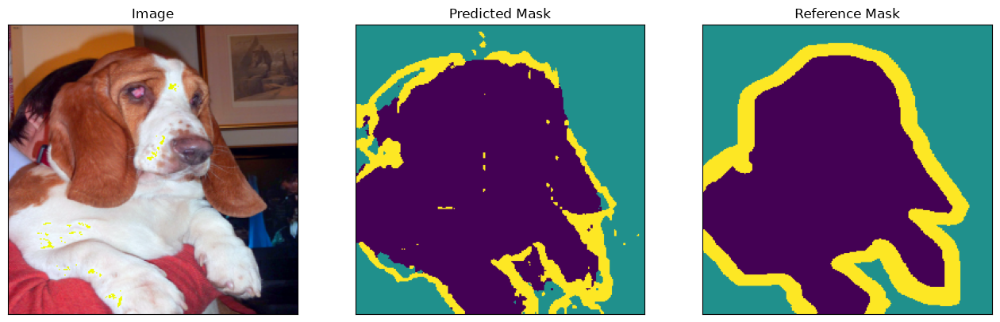

...

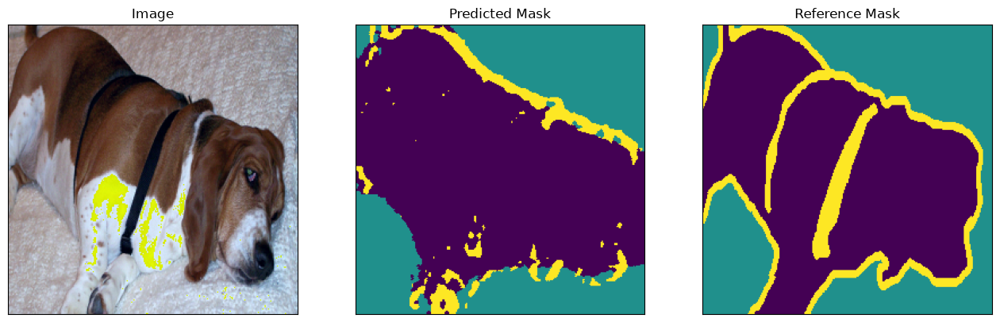

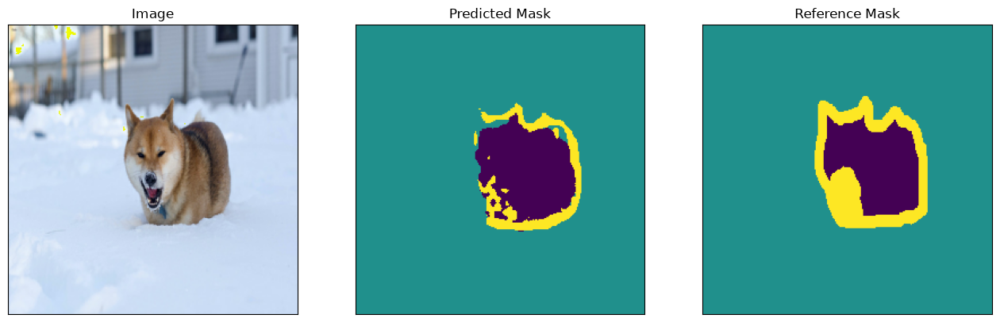

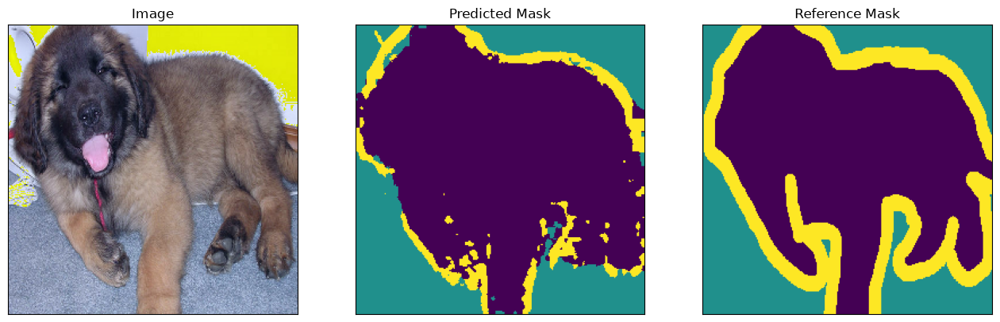

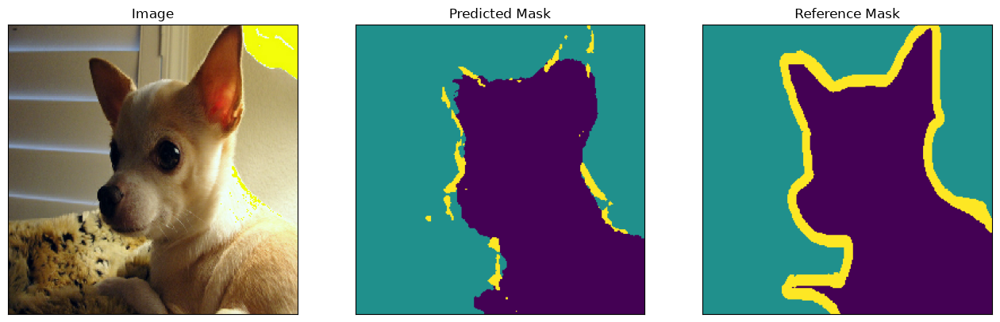

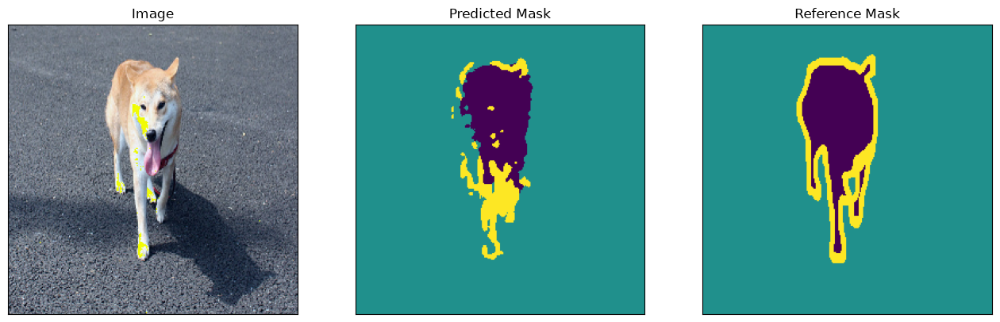

: 

In [ ]:
loader.show_results(model, 16)


## Next steps

- Try one of the other new decoders (PP-LiteSeg, DDRNet) against the same
  MobileOne-S1 backbone - only the `lr_aspp(...)` call needs to change.
- Try a patchify-stem backbone (RepViT, FastViT) here - unlike the
  classification heads, `lr_aspp`/`deeplab_v3_plus`/`pp_liteseg`/`ddrnet`
  already read the backbone's actual built feature-map shape rather than
  assuming a stride formula, so no `deep_layer` stride bug applies to
  segmentation decoders - only `shallow_layer`'s relative position may need
  adjusting for a 4-tap backbone.
- Increase `IMG_SIZE`/epoch counts back toward the original 256x256/20+20 on
  GPU hardware.
